<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 1. Aspectos generales

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Implementa dos variantes avanzadas del modelo RFM clasico:

- **Weighted RFM**: asigna pesos distintos a R, F y M segun la importancia relativa para el negocio.
  En retail de moda (H&M) el gasto (M) y la frecuencia (F) tienen mayor relevancia que la recencia (R).
- **Fuzzy RFM**: reemplaza los cortes duros de quintiles por funciones de pertenencia difusa,
  generando scores continuos en [0, 1] que evitan discontinuidades entre bandas.

Ambos enfoques se calculan sobre las mismas variables RFM base y se combinan en un
score final unificado para la asignacion de segmentos.

Flujo: `silver/merge_pyspark` ---> calculo RFM ---> Weighted scoring ---> Fuzzy scoring
---> score unificado ---> segmentos ---> `gold/rfm_weighted_fuzzy`

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

In [2]:
spark = SparkSession.builder \
    .appName("HYM_Weighted_Fuzzy_RFM") \
    .config("spark.sql.adaptive.enabled", "true") \
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true") \
    .config("spark.driver.memory", "4g") \
    .config("spark.executor.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "50") \
    .config("spark.memory.fraction", "0.8") \
    .getOrCreate()

spark.sparkContext.setCheckpointDir("/tmp/spark_checkpoint")
spark

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 2. Rutas de capas

In [3]:
SILVER = "./silver"
GOLD   = "./gold"

import os
os.makedirs(GOLD, exist_ok=True)

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 3. Carga desde capa silver

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Lee el DataFrame unificado desde `silver/merge_pyspark`.
Solo se seleccionan las columnas necesarias para el calculo RFM:
`customer_id`, `Fecha` y `price`.

In [4]:
%%time
df_raw = spark.read.parquet(f"{SILVER}/merge_pyspark")

df_clean = (
    df_raw
    .select("customer_id", "Fecha", "price")
    .filter(F.col("price").isNotNull())
)

df_clean.createOrReplaceTempView("clean_transactions")
print(f"Registros cargados: {df_clean.count():,}")

Registros cargados: 31,788,324
CPU times: user 2.93 ms, sys: 3.15 ms, total: 6.08 ms
Wall time: 9.33 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 4. Calculo de variables RFM base

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula las tres metricas en una sola pasada SQL:

- **Recency**: dias entre la ultima y penultima compra (ventana `LAG`).
- **Frequency**: numero total de transacciones del cliente.
- **Monetary**: suma del precio pagado por el cliente.

In [5]:
%%time
df_rfm_raw = spark.sql("""
WITH ranked AS (
    SELECT
        customer_id,
        price,
        Fecha,
        LAG(Fecha) OVER (PARTITION BY customer_id ORDER BY Fecha) AS prev_fecha,
        ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY Fecha DESC) AS rnum
    FROM clean_transactions
),
lastbuy AS (
    SELECT customer_id, DATEDIFF(Fecha, prev_fecha) AS Recency
    FROM ranked
    WHERE rnum = 1 AND prev_fecha IS NOT NULL
),
freq_amount AS (
    SELECT
        customer_id,
        COUNT(1)   AS Frequency,
        SUM(price) AS Monetary
    FROM clean_transactions
    GROUP BY customer_id
)
SELECT
    f.customer_id,
    CAST(f.Frequency AS INT)   AS Frequency,
    CAST(f.Monetary      AS FLOAT) AS Monetary,
    CAST(l.Recency      AS INT)   AS Recency
FROM freq_amount f
INNER JOIN lastbuy l ON f.customer_id = l.customer_id
""")

df_rfm_raw = df_rfm_raw.checkpoint()
print(f"Clientes con RFM completo: {df_rfm_raw.count():,}")
df_rfm_raw.describe().show()

Clientes con RFM completo: 914,308
+-------+--------------------+------------------+------------------+------------------+
|summary|         customer_id|         Frequency|          Monetary|           Recency|
+-------+--------------------+------------------+------------------+------------------+
|  count|              914308|            914308|            914308|            914308|
|   mean|                null|33.072049025055016|0.9214713859626225| 95.34116293415347|
| stddev|                null| 44.71914776355066|1.3806829749912866|118.92354897115973|
|    min|00000dbacae5abe5e...|                 2|      0.0033559322|                 1|
|    max|ffffd7744cebcf3ac...|              1895|         57.676407|               731|
+-------+--------------------+------------------+------------------+------------------+

CPU times: user 13.9 ms, sys: 4.35 ms, total: 18.3 ms
Wall time: 46.9 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 5. Scoring por percentiles (base comun)

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula un score discreto 1-5 por quintiles para cada dimension RFM.
Este scoring sirve de base tanto para el Weighted RFM como para el Fuzzy RFM:

- **R_score**: inverso de `Recency` (menor dias = mas reciente = mayor score).
- **F_score**: directo sobre `Frequency`.
- **M_score**: directo sobre `Monetary`.

Adicionalmente se conservan los percentiles crudos (`_pct`) para el calculo fuzzy posterior.

In [6]:
w_r = Window.orderBy(F.col("Recency").asc())        # menor Recency = mas reciente
w_f = Window.orderBy(F.col("Frequency").asc())
w_m = Window.orderBy(F.col("Monetary").asc())

df_pct = (
    df_rfm_raw
    .withColumn("r_pct", F.percent_rank().over(w_r))
    .withColumn("f_pct", F.percent_rank().over(w_f))
    .withColumn("m_pct", F.percent_rank().over(w_m))
)

def quintile_score(col_pct, inverse=False):
    """Asigna score 1-5 segun quintiles. Si inverse=True, quintil bajo = score alto."""
    if inverse:
        return (
            F.when(F.col(col_pct) <= 0.20, 5)
             .when(F.col(col_pct) <= 0.40, 4)
             .when(F.col(col_pct) <= 0.60, 3)
             .when(F.col(col_pct) <= 0.80, 2)
             .otherwise(1)
        )
    return (
        F.when(F.col(col_pct) <= 0.20, 1)
         .when(F.col(col_pct) <= 0.40, 2)
         .when(F.col(col_pct) <= 0.60, 3)
         .when(F.col(col_pct) <= 0.80, 4)
         .otherwise(5)
    )

df_scored = (
    df_pct
    .withColumn("R_score", quintile_score("r_pct", inverse=True))
    .withColumn("F_score", quintile_score("f_pct"))
    .withColumn("M_score", quintile_score("m_pct"))
)

df_scored = df_scored.checkpoint()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 6. Weighted RFM

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

En lugar de promediar R, F y M con pesos iguales (1/3 cada uno), se asignan pesos
que reflejan la prioridad del negocio H&M (retail de moda accesible):

| Dimension | Peso | Justificacion |
|-----------|------|---------------|
| R         | 0.20 | La recencia importa menos: clientes de moda compran por temporadas |
| F         | 0.35 | Alta frecuencia indica fidelidad real al canal |
| M         | 0.45 | El gasto acumulado es el indicador de valor mas directo |

El `weighted_score` resultante esta en el rango [1, 5].
Se mapea a un score discreto 1-5 para poder comparar con el RFM clasico.

In [7]:
W_R = 0.20
W_F = 0.35
W_M = 0.45

df_weighted = (
    df_scored
    .withColumn(
        "weighted_score",
        F.col("R_score") * W_R +
        F.col("F_score") * W_F +
        F.col("M_score") * W_M
    )
    # Discretizar el score ponderado en 5 niveles para segmentacion
    .withColumn(
        "weighted_segment",
        F.when(F.col("weighted_score") <= 1.8, "bajo")
         .when(F.col("weighted_score") <= 2.6, "medio_bajo")
         .when(F.col("weighted_score") <= 3.4, "medio")
         .when(F.col("weighted_score") <= 4.2, "medio_alto")
         .otherwise("alto")
    )
)

df_weighted.select("customer_id", "R_score", "F_score", "M_score",
                   "weighted_score", "weighted_segment").show(10)

+--------------------+-------+-------+-------+------------------+----------------+
|         customer_id|R_score|F_score|M_score|    weighted_score|weighted_segment|
+--------------------+-------+-------+-------+------------------+----------------+
|8da3c78f3442d8a53...|      5|      1|      1|               1.8|            bajo|
|da11b72bc3aa27e94...|      3|      1|      1|1.4000000000000001|            bajo|
|58bcdb2e5b8395e85...|      5|      1|      1|               1.8|            bajo|
|5e788693417037eb8...|      5|      1|      1|               1.8|            bajo|
|59da67012cc4f43ee...|      2|      1|      1|               1.2|            bajo|
|866c9fb1c887eab0d...|      4|      1|      1|1.5999999999999999|            bajo|
|0aa8dcb87dddb4fff...|      5|      1|      1|               1.8|            bajo|
|8e47f23d46b58baba...|      5|      1|      1|               1.8|            bajo|
|c1be160d24051530e...|      2|      1|      1|               1.2|            bajo|
|861

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 7. Fuzzy RFM

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

El RFM clasico asigna el mismo score a clientes en los extremos opuestos de un quintil.
Fuzzy RFM resuelve esto con **funciones de pertenencia trapezoidales** que generan
un score continuo en [0, 1] por cada nivel linguistico {muy_bajo, bajo, medio, alto, muy_alto}.

Implementacion en Spark: se usan los percentiles crudos (`_pct`) calculados anteriormente
como entrada a las funciones trapezoidales. El score fuzzy final de cada dimension
es el **centroide ponderado** (defuzzificacion por centro de masa):

```
fuzzy_score = SUM(nivel * mu_nivel) / SUM(mu_nivel)   para nivel in {1,2,3,4,5}
```

El score fuzzy resultante esta en [1, 5], igual que el clasico, pero es continuo.

In [8]:
def trapezoidal(col_name, a, b, c, d):
    """
    Funcion de pertenencia trapezoidal definida por [a, b, c, d].
    Retorna una columna Spark con valores en [0, 1].
    - [a, b]: rampa ascendente
    - [b, c]: meseta (pertenencia = 1)
    - [c, d]: rampa descendente
    """
    x = F.col(col_name)
    ramp_up   = (x - a) / (b - a + 1e-9)
    ramp_down = (d - x) / (d - c + 1e-9)
    return (
        F.when(x <= a, 0.0)
         .when(x <= b, ramp_up)
         .when(x <= c, 1.0)
         .when(x <= d, ramp_down)
         .otherwise(0.0)
    )

# Funciones trapezoidales para 5 niveles sobre el rango [0, 1] del percentil
# Los limites se definen con solapamiento para suavizar las transiciones
trapezoids = {
    1: (0.00, 0.00, 0.10, 0.30),   # muy_bajo
    2: (0.10, 0.25, 0.35, 0.50),   # bajo
    3: (0.35, 0.45, 0.55, 0.65),   # medio
    4: (0.50, 0.65, 0.75, 0.90),   # alto
    5: (0.70, 0.90, 1.00, 1.00),   # muy_alto
}

def fuzzy_score(pct_col):
    """Defuzzificacion por centro de masa sobre el percentil dado."""
    numerator   = F.lit(0.0)
    denominator = F.lit(0.0)
    for level, (a, b, c, d) in trapezoids.items():
        mu = trapezoidal(pct_col, a, b, c, d)
        numerator   = numerator   + (F.lit(float(level)) * mu)
        denominator = denominator + mu
    return numerator / (denominator + F.lit(1e-9))

# Para Recency se invierte el percentil (menor Recency = mejor)
df_fuzzy = (
    df_scored
    .withColumn("r_pct_inv", F.lit(1.0) - F.col("r_pct"))   # inversion de recencia
    .withColumn("R_fuzzy", fuzzy_score("r_pct_inv"))
    .withColumn("F_fuzzy", fuzzy_score("f_pct"))
    .withColumn("M_fuzzy", fuzzy_score("m_pct"))
)

df_fuzzy = df_fuzzy.checkpoint()
df_fuzzy.select("customer_id", "R_fuzzy", "F_fuzzy", "M_fuzzy").show(10)

+--------------------+------------------+------------------+------------------+
|         customer_id|           R_fuzzy|           F_fuzzy|           M_fuzzy|
+--------------------+------------------+------------------+------------------+
|8da3c78f3442d8a53...|       4.999999995|               0.0|               0.0|
|da11b72bc3aa27e94...|3.2167985661582037|               0.0|0.9999999989999999|
|58bcdb2e5b8395e85...|       4.999999995|               0.0|0.9999999989999999|
|5e788693417037eb8...|       4.999999995|               0.0|0.9999999989999999|
|59da67012cc4f43ee...|1.5740333143255485|0.9999999989999999|0.9999999989999999|
|866c9fb1c887eab0d...| 4.095128542939411|               0.0|0.9999999989999999|
|0aa8dcb87dddb4fff...|4.7771298349128495|               0.0|0.9999999989999999|
|8e47f23d46b58baba...|       4.999999995|               0.0|0.9999999989999999|
|c1be160d24051530e...|2.1767834243749986|0.9999999989999999|0.9999999989999999|
|861717e1c0f0837de...| 4.315607174257642

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 8. Score unificado Weighted-Fuzzy

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Combina los scores fuzzy de cada dimension aplicando los mismos pesos de negocio
definidos en el paso anterior (W_R=0.20, W_F=0.35, W_M=0.45).

El `wf_score` resultante hereda tanto la suavidad de la logica difusa
como la importancia relativa de cada dimension segun el negocio.

Segmentacion final en cinco niveles de valor de cliente:

| wf_score    | Segmento         |
|-------------|------------------|
| <= 1.8      | perdido          |
| <= 2.6      | en_riesgo        |
| <= 3.4      | potencial        |
| <= 4.2      | leal             |
| > 4.2       | campeon          |

In [9]:
df_final = (
    df_fuzzy
    .join(
        df_weighted.select("customer_id", "weighted_score", "weighted_segment"),
        "customer_id", "inner"
    )
    .withColumn(
        "wf_score",
        F.col("R_fuzzy") * W_R +
        F.col("F_fuzzy") * W_F +
        F.col("M_fuzzy") * W_M
    )
    .withColumn(
        "wf_segment",
        F.when(F.col("wf_score") <= 1.8, "perdido")
         .when(F.col("wf_score") <= 2.6, "en_riesgo")
         .when(F.col("wf_score") <= 3.4, "potencial")
         .when(F.col("wf_score") <= 4.2, "leal")
         .otherwise("campeon")
    )
    .select(
        "customer_id", "Recency", "Frequency", "Monetary",
        "R_score", "F_score", "M_score",
        "R_fuzzy", "F_fuzzy", "M_fuzzy",
        "weighted_score", "weighted_segment",
        "wf_score", "wf_segment"
    )
)

df_final = df_final.checkpoint()
df_final.show(10)

+--------------------+-------+---------+----------+-------+-------+-------+------------------+------------------+------------------+--------------+----------------+------------------+----------+
|         customer_id|Recency|Frequency|  Monetary|R_score|F_score|M_score|           R_fuzzy|           F_fuzzy|           M_fuzzy|weighted_score|weighted_segment|          wf_score|wf_segment|
+--------------------+-------+---------+----------+-------+-------+-------+------------------+------------------+------------------+--------------+----------------+------------------+----------+
|0000945f66de1a11d...|    249|        3|0.09316949|      1|      1|      1| 1.061218015751759|0.9999999989999999|0.9999999989999999|           1.0|            bajo|1.0122436023503518|   perdido|
|00009c2aeae8761f7...|    630|        5|0.09298305|      1|      1|      1|0.9999999989999999|0.9999999989999999|0.9999999989999999|           1.0|            bajo|0.9999999989999999|   perdido|
|0000d6c053fc8f938...|   

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 9. Analisis de segmentos

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Perfil de los segmentos Weighted-Fuzzy: numero de clientes, frecuencia media,
gasto medio y recencia media por segmento.

In [10]:
perfil_seg = (
    df_final.groupBy("wf_segment")
    .agg(
        F.count("customer_id").alias("n_clientes"),
        F.avg("Frequency").alias("freq_media"),
        F.avg("Monetary").alias("Monetary_media"),
        F.avg("Recency").alias("Recency_media"),
        F.avg("wf_score").alias("wf_score_medio")
    )
    .orderBy(F.col("wf_score_medio").desc())
)

perfil_seg.show(truncate=False)

+----------+----------+-----------------+------------------+------------------+------------------+
|wf_segment|n_clientes|freq_media       |Monetary_media    |Recency_media     |wf_score_medio    |
+----------+----------+-----------------+------------------+------------------+------------------+
|campeon   |190019    |93.73602113472863|2.71081870794955  |27.964087801746143|4.613727977866942 |
|leal      |182224    |34.92491109842831|0.9331350258184946|68.95384252348758 |3.8131978552490686|
|potencial |153033    |19.21397999124372|0.5040216248535265|91.79993204080165 |2.997581410140603 |
|en_riesgo |191278    |10.77109756480097|0.2791024418029791|99.57975302962181 |2.1880169196983474|
|perdido   |197754    |5.368336417973846|0.1357439281465791|183.03852260889792|1.3966420961095487|
+----------+----------+-----------------+------------------+------------------+------------------+



<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 10. Visualizacion

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Graficos de distribucion de clientes, gasto medio y frecuencia media por segmento Weighted-Fuzzy.

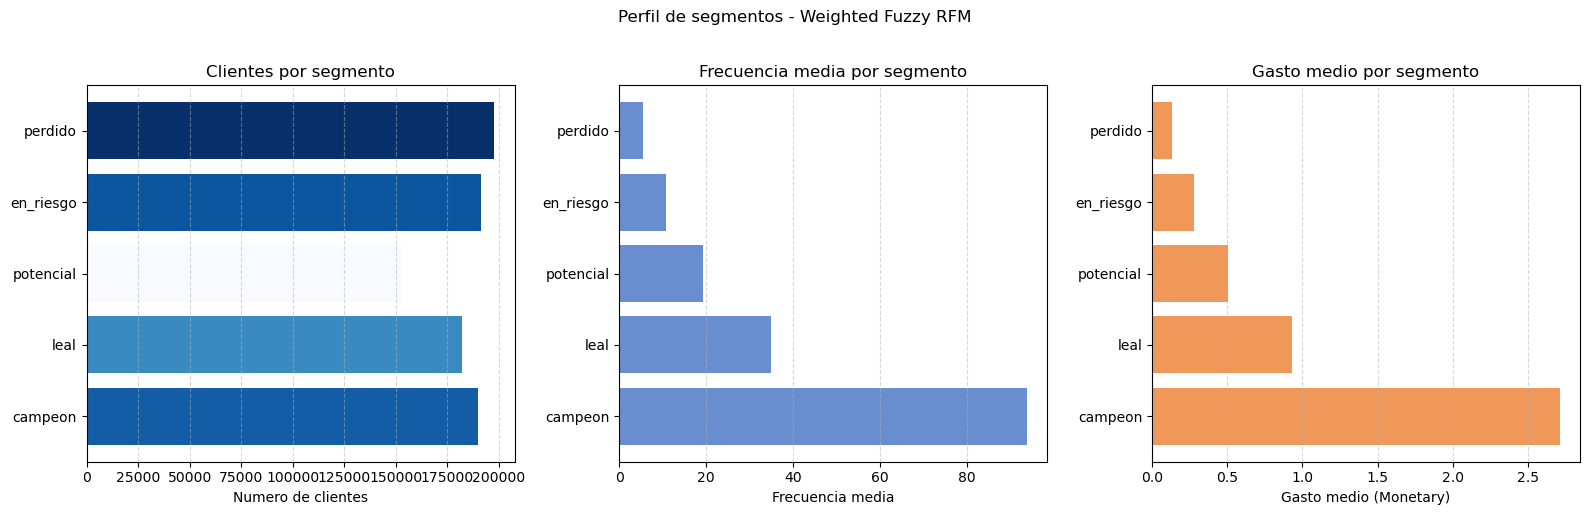

In [11]:
perf_pd = perfil_seg.toPandas().set_index("wf_segment")

norm   = plt.Normalize(perf_pd["n_clientes"].min(), perf_pd["n_clientes"].max())
colors = plt.cm.Blues(norm(perf_pd["n_clientes"].values))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].barh(perf_pd.index, perf_pd["n_clientes"], color=colors)
axes[0].set_xlabel("Numero de clientes")
axes[0].set_title("Clientes por segmento")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

axes[1].barh(perf_pd.index, perf_pd["freq_media"], color="#4472C4", alpha=0.8)
axes[1].set_xlabel("Frecuencia media")
axes[1].set_title("Frecuencia media por segmento")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

axes[2].barh(perf_pd.index, perf_pd["Monetary_media"], color="#ED7D31", alpha=0.8)
axes[2].set_xlabel("Gasto medio (Monetary)")
axes[2].set_title("Gasto medio por segmento")
axes[2].grid(axis="x", linestyle="--", alpha=0.5)

fig.suptitle("Perfil de segmentos - Weighted Fuzzy RFM", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Heatmap de scores medios R, F, M (fuzzy) por segmento para comparar
el perfil dimensional de cada grupo.

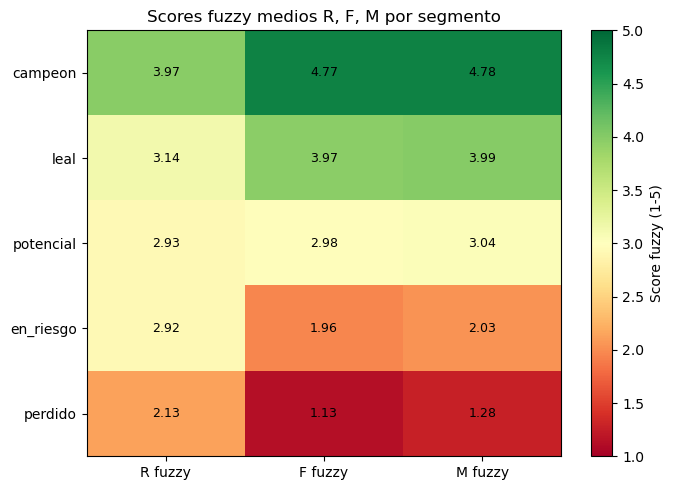

In [12]:
score_pd = (
    df_final.groupBy("wf_segment")
    .agg(
        F.avg("R_fuzzy").alias("R"),
        F.avg("F_fuzzy").alias("F"),
        F.avg("M_fuzzy").alias("M")
    )
    .orderBy(F.col("M").desc())
    .toPandas()
    .set_index("wf_segment")
)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(score_pd.values, cmap="RdYlGn", aspect="auto", vmin=1, vmax=5)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["R fuzzy", "F fuzzy", "M fuzzy"])
ax.set_yticks(range(len(score_pd)))
ax.set_yticklabels(score_pd.index)
for i in range(len(score_pd)):
    for j in range(3):
        ax.text(j, i, f"{score_pd.values[i, j]:.2f}",
                ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="Score fuzzy (1-5)")
ax.set_title("Scores fuzzy medios R, F, M por segmento")
plt.tight_layout()
plt.show()

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Comparacion de la distribucion del score continuo entre Weighted RFM clasico
y Weighted-Fuzzy RFM sobre una muestra del 5 % para evidenciar la suavizacion
que aporta la logica difusa.

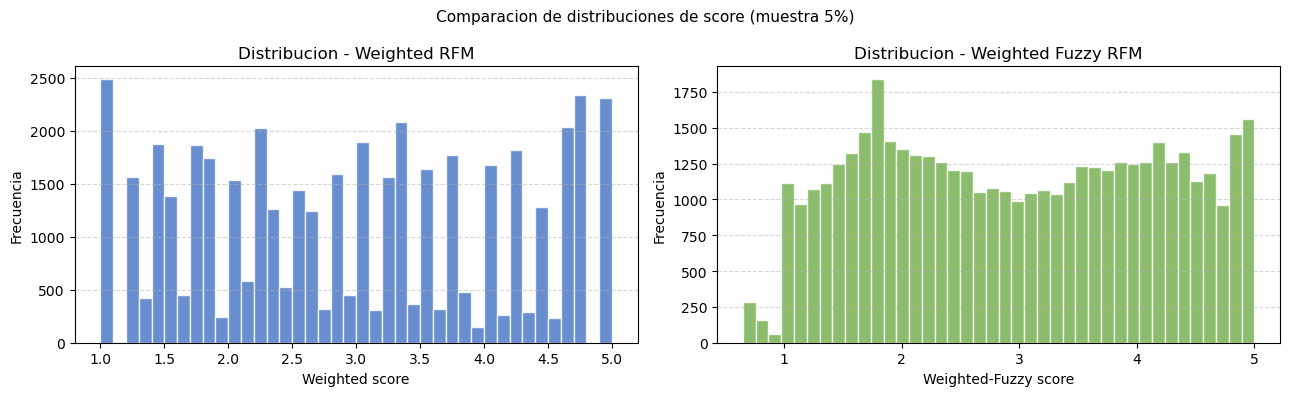

In [13]:
sample_pd = (
    df_final
    .select("weighted_score", "wf_score")
    .sample(fraction=0.05, seed=42)
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(sample_pd["weighted_score"], bins=40, color="#4472C4", alpha=0.8, edgecolor="white")
axes[0].set_xlabel("Weighted score")
axes[0].set_ylabel("Frecuencia")
axes[0].set_title("Distribucion - Weighted RFM")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].hist(sample_pd["wf_score"], bins=40, color="#70AD47", alpha=0.8, edgecolor="white")
axes[1].set_xlabel("Weighted-Fuzzy score")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("Distribucion - Weighted Fuzzy RFM")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

fig.suptitle("Comparacion de distribuciones de score (muestra 5%)", fontsize=11)
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 11. Escritura en capa gold

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Guarda el DataFrame final con ambas segmentaciones en `gold/rfm_weighted_fuzzy`.

In [14]:
df_final.write.mode("overwrite").parquet(f"{GOLD}/rfm_weighted_fuzzy")
print("Escritura en gold/rfm_weighted_fuzzy completada")

spark.read.parquet(f"{GOLD}/rfm_weighted_fuzzy") \
    .groupBy("wf_segment").count() \
    .orderBy(F.col("count").desc()) \
    .show()

Escritura en gold/rfm_weighted_fuzzy completada
+----------+------+
|wf_segment| count|
+----------+------+
|   perdido|197754|
| en_riesgo|191278|
|   campeon|190019|
|      leal|182224|
| potencial|153033|
+----------+------+



In [15]:
spark.stop()